# Olist E-commerce Customer Analysis (EDA)
## Objective

Analyze the Olist customer dataset to understand geographic distribution, 
customer frequency, and retention patterns.

## Dataset


- Source: Olist Brazilian E-Commerce (Kaggle)
- Rows: 99,441 | Columns: 5 (4 categorical, 1 integer)
- Timeframe: This dataset has information of 100k orders from 2016 to 2018 made at multiple marketplaces in Brazil.

# Findings from Data

In the Olist dataset, the two IDs answer different questions:

1. customer_id is a key that links to the orders table. Olist generates a new customer_id for every order, so it identifies the order-customer pairing and not the person.
2. customer_unique_id identifies the actual person. The same person always has the same customer_unique_id, across all of their orders.
3. One of our top customers in this dataset is from São Paulo.
4. A total of 27 unique states and 4,119 unique cities are present.
5. The number of unique customers is 96,096 out of 99,441 transactions.
6. Order volume is heavily concentrated in São Paulo (SP), which has far more orders than any other state. The remaining states each contribute only a small share, which shows a strong geographic imbalance in the customer base.

7. Repeat-purchase rate is low across all states (about 3% on average), with little difference between major states. Retention is a company-wide challenge, not a regional one.

8. Customer volume is heavily concentrated in a few large cities. São Paulo alone accounts for about 15.6% of all customers, and the top two cities (São Paulo and Rio de Janeiro) together account for about 22%. The top 15 cities represent roughly 39% of the customer base, and 7 of them are in São Paulo state, many within the Greater São Paulo metro area. This shows a strong urban and regional concentration in the business.

Business Insights -

a. Opportunity: the long tail of smaller cities holds most customers but each city is small, so growth there is harder to target.
b. Risk: heavy dependence on SP and Rio means any delivery or demand problem there hurts the whole business.

1. Order frequency is highly skewed. A single customer placed 17 orders, another placed 9, and a handful placed 7, but these are rare exceptions. The vast majority of the 96,096 customers ordered only once. The gap between one-time customers and repeat customers is very large, which suggests that customer retention is low and most revenue comes from first-time purchases.

**Limitation**: A full RFM (Recency, Frequency, Monetary) analysis cannot be performed on the customer table alone, because it contains no date or payment information. Only the Frequency component is available here.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("olist_customers_dataset.csv")
df.head(10)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP
7,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
9,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG


In [3]:
print(df.isnull().sum())
print(df.duplicated().sum())

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64
0


In [4]:
df.shape

(99441, 5)

In [5]:
df['customer_id'].duplicated().sum()

np.int64(0)

No duplicate customer_order_id means the data is clean and accurate. It shows only distinct transactions of orders with customers.

In [6]:
df['customer_unique_id'].duplicated().sum()

np.int64(3345)

The customer_unique_id can repeat because a single customer can place multiple orders.

In [7]:
df['customer_zip_code_prefix'].duplicated().sum()

np.int64(84447)

In [8]:
df = df.rename(columns={'customer_id':'customer_order_id'})

In [9]:
df

,customer_order_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
...,...,...,...,...,...
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS


In [10]:
print(df['customer_state'].unique(),'\n', df['customer_state'].nunique())
print("\n")
print(df['customer_city'].unique(),'\n', df['customer_city'].nunique())

<ArrowStringArray>
['SP', 'SC', 'MG', 'PR', 'RJ', 'RS', 'PA', 'GO', 'ES', 'BA', 'MA', 'MS', 'CE',
 'DF', 'RN', 'PE', 'MT', 'AM', 'AP', 'AL', 'RO', 'PB', 'TO', 'PI', 'AC', 'SE',
 'RR']
Length: 27, dtype: str 
 27


<ArrowStringArray>
[               'franca', 'sao bernardo do campo',             'sao paulo',
       'mogi das cruzes',              'campinas',        'jaragua do sul',
               'timoteo',              'curitiba',        'belo horizonte',
         'montes claros',
 ...
              'balbinos',          'serra bonita',          'venda branca',
           'sanga puita',               'queiroz',                'siriji',
   'natividade da serra',          'monte bonito',            'sao rafael',
     'eugenio de castro']
Length: 4119, dtype: str 
 4119


A total of 27 unique states and 4,119 unique cities are present.

### Key Questions & Analysis Direction:

1. Can I find from which state most of the sales are coming?
Ans: For that, I need to check and arrange the states.

2. I am not focusing on zip codes because zip codes show a much finer version of the location. If I were to work with that, I would need to find regions or calculate distances between those addresses to understand why and where sales are coming from more or less. That would be a lengthy and hectic process, so I am going to drop that idea.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_order_id         99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB


4 categorical features and 1 integer column.

In [12]:
# Let's rearrange the data by state
df.sort_values('customer_state', inplace=True)
df = df.reset_index()
df.head(10)

,index,customer_order_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,828,94906d652f7d1c9e4c4af604ede7784b,544d0f13064dc42b8f6957cf43fa5cad,69918,rio branco,AC
1,1684,ca077dd95290191565abb393a580bbfc,70f326d437e44cf69da00c9169b74fb3,69911,rio branco,AC
2,2638,5a5f70fead43dc16ec4d5afed5281239,b1cf91f7efd99001549d2eafa05c66c1,69918,rio branco,AC
3,4937,c5de7db594b246f428940ced283125bd,8c792a4fb7f5d708257abf55fa899ce8,69918,rio branco,AC
4,5674,16aba5570b45f6b4c9204407132e2cae,5f8f12098427d3cbb37e9dcf269bb53c,69918,rio branco,AC
5,6877,6b04ea93ce93cef2a5fbdfe302e21331,c73db85789b600b05c503d21441940f9,69918,rio branco,AC
6,7484,2201362e68992f654942dc0067c1b716,f7d7fc0a59ef4363fdce6e3aa069d498,69900,rio branco,AC
7,9455,31dbc13addc753e210692eacaea065e4,5dbba6c01268a8ad43f79157bf4454a0,69900,rio branco,AC
8,9630,5a0dc6805a195218a4e448653dee4740,89fd593957ef80a12f0588913e78b00d,69915,rio branco,AC
9,12385,5c495510e9f861b83aa5fb7c308e8d76,28989ef45087c96e5a4346e88216c2ba,69912,rio branco,AC


In [13]:
# Frequency of orders per unique customer
print('The number of unique customers is', df['customer_unique_id'].nunique(), 'out of 99441 transactions')

The number of unique customers is 96096 out of 99441 transactions


# State-Wise Analysis

In [14]:
customer_orders = df['customer_unique_id'].value_counts().reset_index()
customer_orders.columns = ['customer_unique_id', 'order_count']
customer_orders.head()

,customer_unique_id,order_count
0,8d50f5eadf50201ccdcedfb9e2ac8455,17
1,3e43e6105506432c953e165fb2acf44c,9
2,1b6c7548a2a1f9037c1fd3ddfed95f33,7
3,ca77025e7201e3b30c44b472ff346268,7
4,6469f99c1f9dfae7733b25662e7f1782,7


Total 27 unique states are present in the dataset


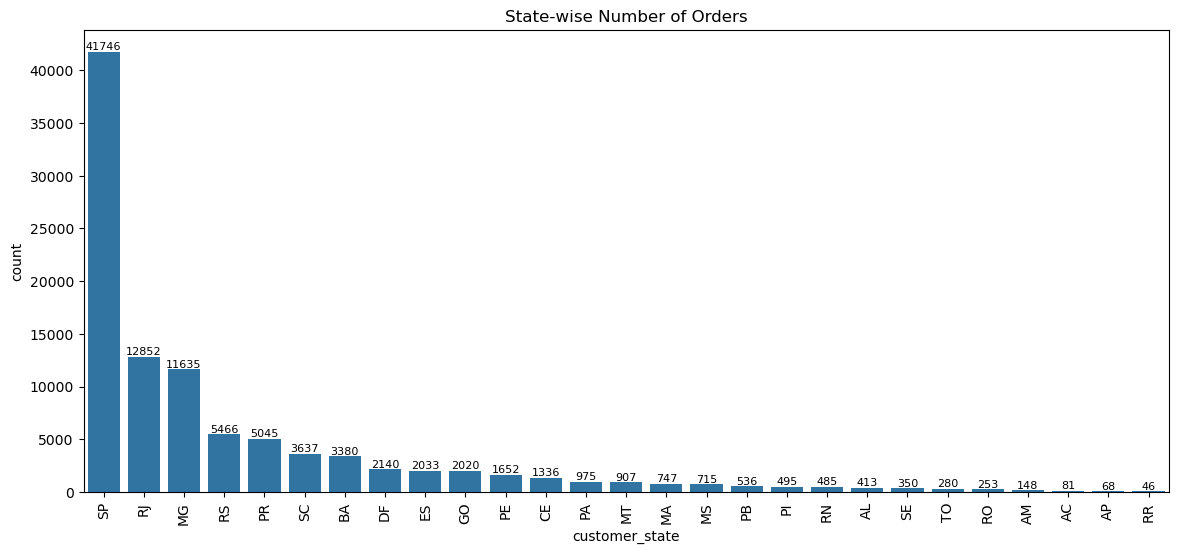

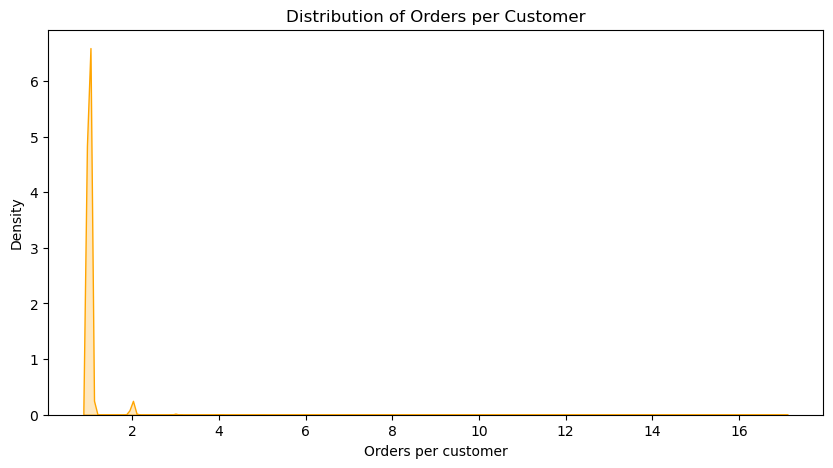

In [15]:
# State-wise analysis
print (f"Total {df['customer_state'].nunique()} unique states are present in the dataset")\

plt.figure(figsize=(14, 6))
ax = sns.countplot(data=df, x='customer_state', order=df['customer_state'].value_counts().index)
ax.bar_label(ax.containers[0], fontsize=8)
plt.title('State-wise Number of Orders')
plt.xticks(rotation=90)
plt.show()
plt.figure(figsize=(10, 5))
sns.kdeplot(data=customer_orders, x='order_count', fill=True, bw_adjust=2, color='orange')
plt.title('Distribution of Orders per Customer')
plt.xlabel('Orders per customer')
plt.show()

Order volume is heavily concentrated in São Paulo (SP), which has far more orders than any other state. The remaining states each contribute only a small share, which shows a strong geographic imbalance in the customer base.

In [16]:
top_id = customer_orders.loc[0, 'customer_unique_id']
df[df['customer_unique_id'] == top_id][['customer_city', 'customer_state']].drop_duplicates()

,customer_city,customer_state
63398,sao paulo,SP


Our top customer is located in São Paulo.

In [17]:
# 1. build the customer table
customer_orders = df['customer_unique_id'].value_counts().reset_index()
customer_orders.columns = ['customer_unique_id', 'order_count']

# 2. add the state 
state_map = df[['customer_unique_id', 'customer_state']].drop_duplicates('customer_unique_id')
customer_orders = customer_orders.merge(state_map, on='customer_unique_id')


In [18]:
rate = (customer_orders['order_count'] > 1).groupby(customer_orders['customer_state']).mean() * 100
rate = rate.sort_values(ascending=False)

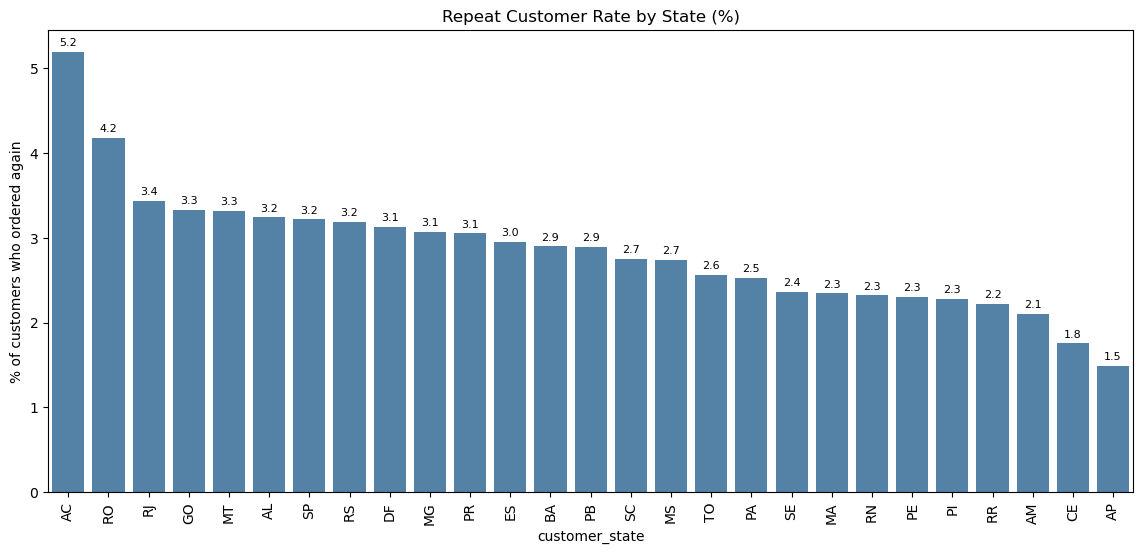

In [19]:
rate = (customer_orders['order_count'] > 1).groupby(customer_orders['customer_state']).mean() * 100
rate = rate.sort_values(ascending=False)

plt.figure(figsize=(14, 6))
ax = sns.barplot(x=rate.index, y=rate.values, color='steelblue')
ax.bar_label(ax.containers[0], fmt='%.1f', fontsize=8, padding=3)
plt.xticks(rotation=90)
plt.title('Repeat Customer Rate by State (%)')
plt.ylabel('% of customers who ordered again')
plt.show()

Repeat-purchase rate is low across all states (about 3% on average), with little difference between major states. Retention is a company-wide challenge, not a regional one.

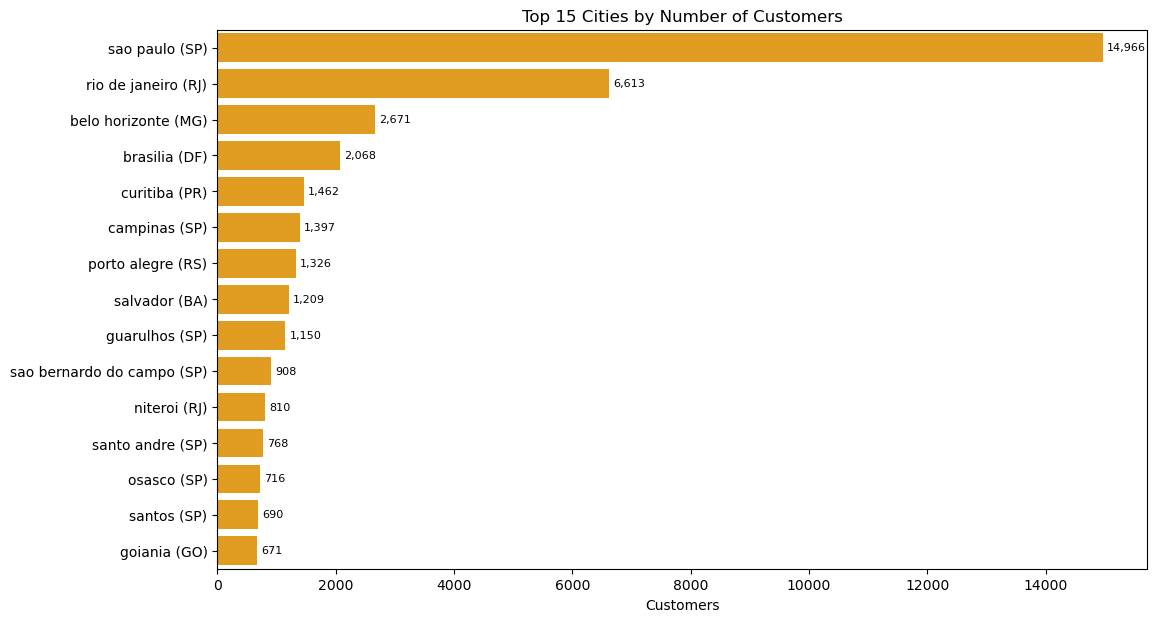

In [20]:
city_df = (df.drop_duplicates('customer_unique_id')
             .groupby(['customer_state', 'customer_city'])['customer_unique_id']
             .count().reset_index(name='customers'))

top = city_df.sort_values('customers', ascending=False).head(15)
top['label'] = top['customer_city'] + ' (' + top['customer_state'] + ')'

plt.figure(figsize=(12, 7))
ax = sns.barplot(data=top, y='label', x='customers', color='orange')
ax.bar_label(ax.containers[0], fmt='{:,.0f}', padding=3, fontsize=8)
plt.title('Top 15 Cities by Number of Customers')
plt.xlabel('Customers')
plt.ylabel('')
plt.show()

Customer volume is heavily concentrated in a few large cities. São Paulo alone accounts for about 15.6% of all customers, and the top two cities (São Paulo and Rio de Janeiro) together account for about 22%. The top 15 cities represent roughly 39% of the customer base, and 7 of them are in São Paulo state, many within the Greater São Paulo metro area. This shows a strong urban and regional concentration in the business.

**Business Insights** -

1. Opportunity: the long tail of smaller cities holds most customers but each city is small, so growth there is harder to target.
2. Risk: heavy dependence on SP and Rio means any delivery or demand problem there hurts the whole business.

# Customer-Wise Analysis

In [21]:
df['customer_unique_id'].value_counts()

customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    17
3e43e6105506432c953e165fb2acf44c     9
1b6c7548a2a1f9037c1fd3ddfed95f33     7
ca77025e7201e3b30c44b472ff346268     7
6469f99c1f9dfae7733b25662e7f1782     7
                                    ..
1f4b29fb78faa282b122b491ce721aaa     1
721406d1edfabad2de3f86155356d8e0     1
7c0b4f7719caf8b29a4c8dbd5a1446c9     1
fa0d24dd602c76038e9c0614d1620cec     1
0465f164e35aba70f70e911b252513a9     1
Name: count, Length: 96096, dtype: int64

In [22]:
df['customer_unique_id'].nunique()

96096

In [23]:
customer_orders = df['customer_unique_id'].value_counts().reset_index()
customer_orders.columns = ['customer_unique_id', 'order_count']
customer_orders.head()

,customer_unique_id,order_count
0,8d50f5eadf50201ccdcedfb9e2ac8455,17
1,3e43e6105506432c953e165fb2acf44c,9
2,1b6c7548a2a1f9037c1fd3ddfed95f33,7
3,ca77025e7201e3b30c44b472ff346268,7
4,6469f99c1f9dfae7733b25662e7f1782,7


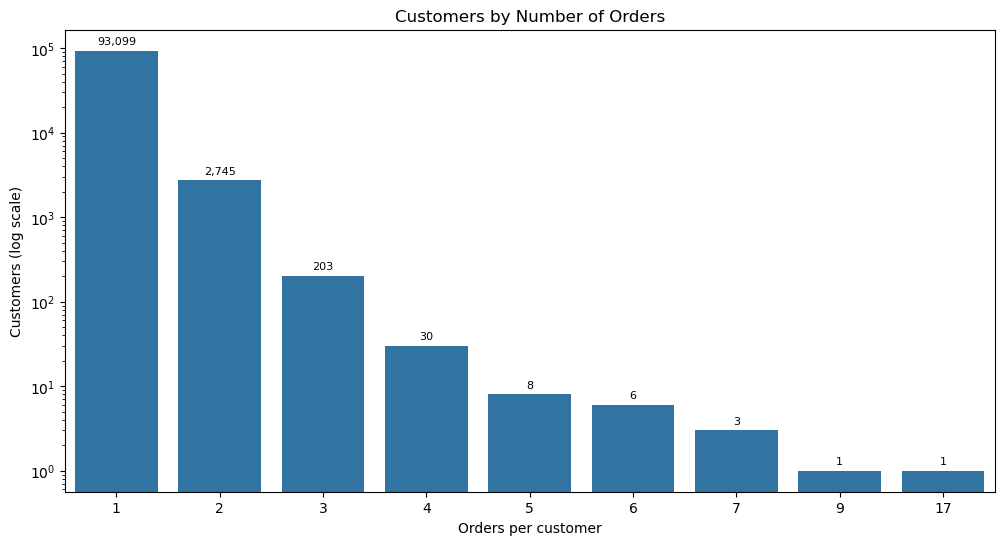

In [24]:
counts = customer_orders['order_count'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=counts.index, y=counts.values)
ax.bar_label(ax.containers[0], fmt='{:,.0f}', fontsize=8, padding=3)
plt.yscale('log')
plt.title('Customers by Number of Orders')
plt.xlabel('Orders per customer')
plt.ylabel('Customers (log scale)')
plt.show()

Order frequency is highly skewed. A single customer placed 17 orders, another placed 9, and a handful placed 7, but these are rare exceptions. The vast majority of the 96,096 customers ordered only once. The gap between one-time customers and repeat customers is very large, which suggests that customer retention is low and most revenue comes from first-time purchases.

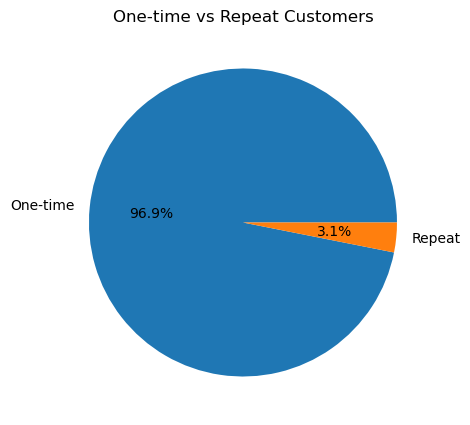

In [25]:
repeat = (customer_orders['order_count'] > 1).map({False: 'One-time', True: 'Repeat'})
repeat.value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(5, 5))
plt.ylabel('')
plt.title('One-time vs Repeat Customers')
plt.show()

Customer frequency is low. Only about 3.1% of customers placed a second order, while the remaining ~97% bought just once. The business should focus on improving customer retention, for example through follow-up offers, loyalty rewards, or better post-purchase engagement.

Limitation: A full RFM (Recency, Frequency, Monetary) analysis cannot be performed on the customer table alone, because it contains no date or payment information. Only the Frequency component is available here.

The low repeat-purchase rate is likely driven by several factors, which this table cannot confirm. Possible contributors include:

1. Delivery experience: late or unreliable deliveries may discourage a second order.
2. Returns and refund policy: friction or disputes in the return process may reduce trust.
3. Competitive alternatives: customers may have found better prices or product selection elsewhere.

These are hypotheses, not conclusions, and need further analysis to test.

# Future Scope & Recommendations

Future Scope and Recommendations

Zip Code Analysis (not pursued in this project)

The zip code prefix gives a finer view of location than city or state. Using it would require mapping each prefix to coordinates (via the geolocation table) and calculating distances, which is a lengthy process outside the scope of this EDA. Potential insights if pursued later:

1. Delivery performance: Calculating the real distance between seller and customer could confirm whether long distances are linked to delivery delays and poor customer experience.
2. Regional demand: Analyzing product value by location could reveal high-potential regions, which could help increase sales through targeted marketing.

Feedback System

1. Feedback from repeat customers: Customers who purchased more than once should be encouraged to share feedback, as should one-time customers. This helps the company understand both its strengths and its weaknesses.
2. Post-delivery feedback: Request feedback automatically after each order is delivered.
3. Open-box delivery: Adopt an open-box delivery model, where the customer inspects the product at handover.
4. Delivery-time verification: The delivery agent should confirm with the customer that the product matches the order and expectations, and record a clear reason if it does not.